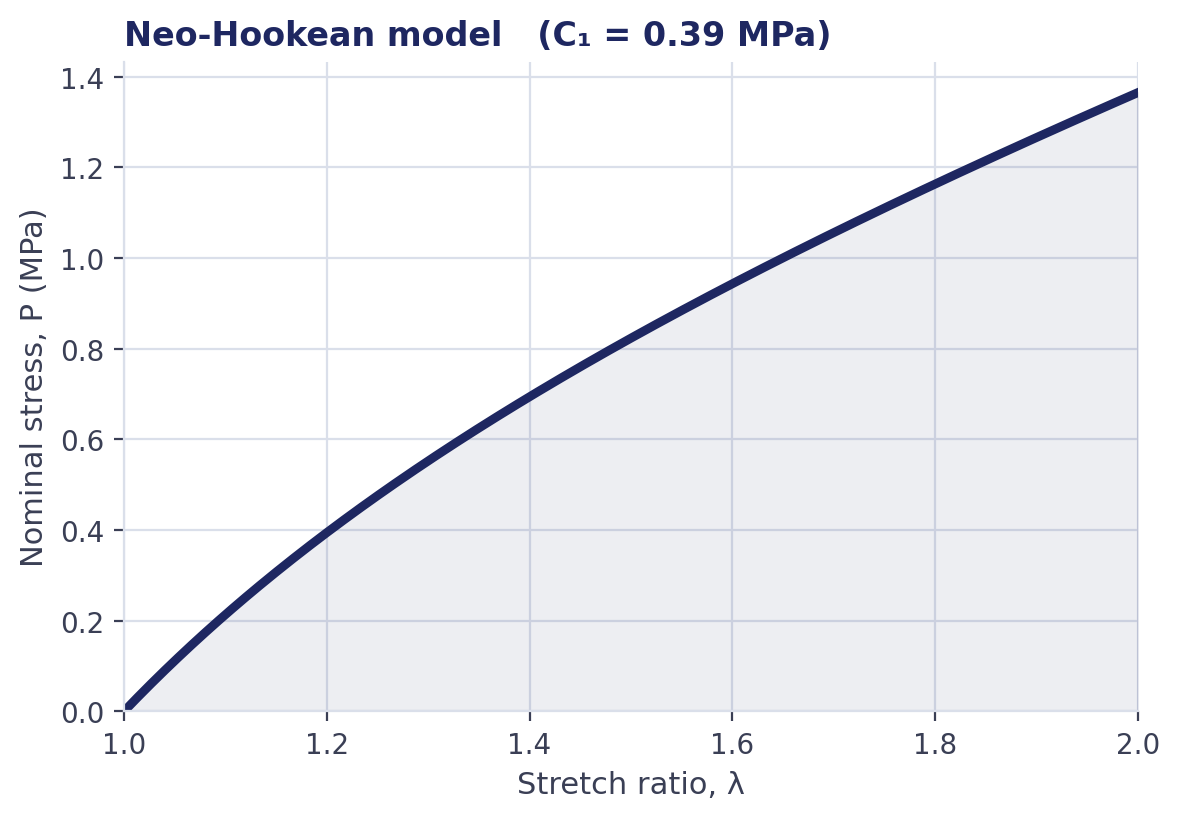

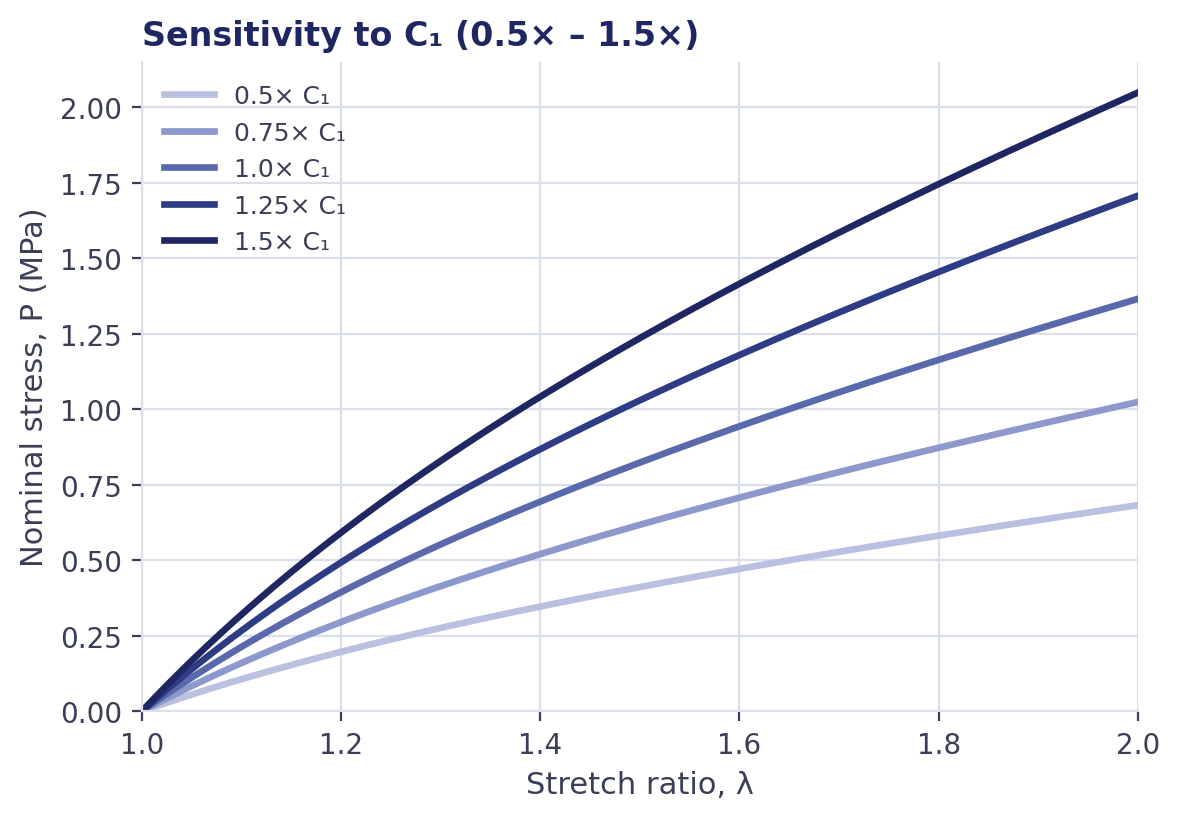

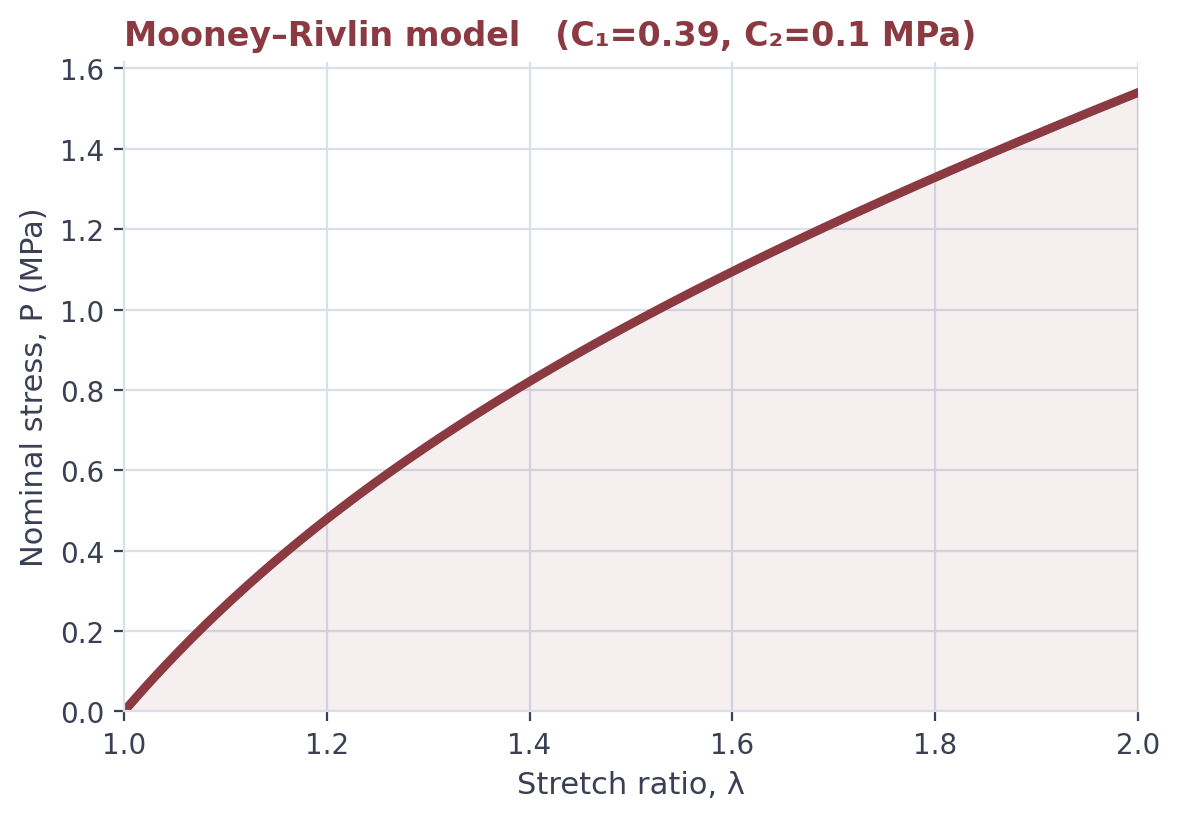

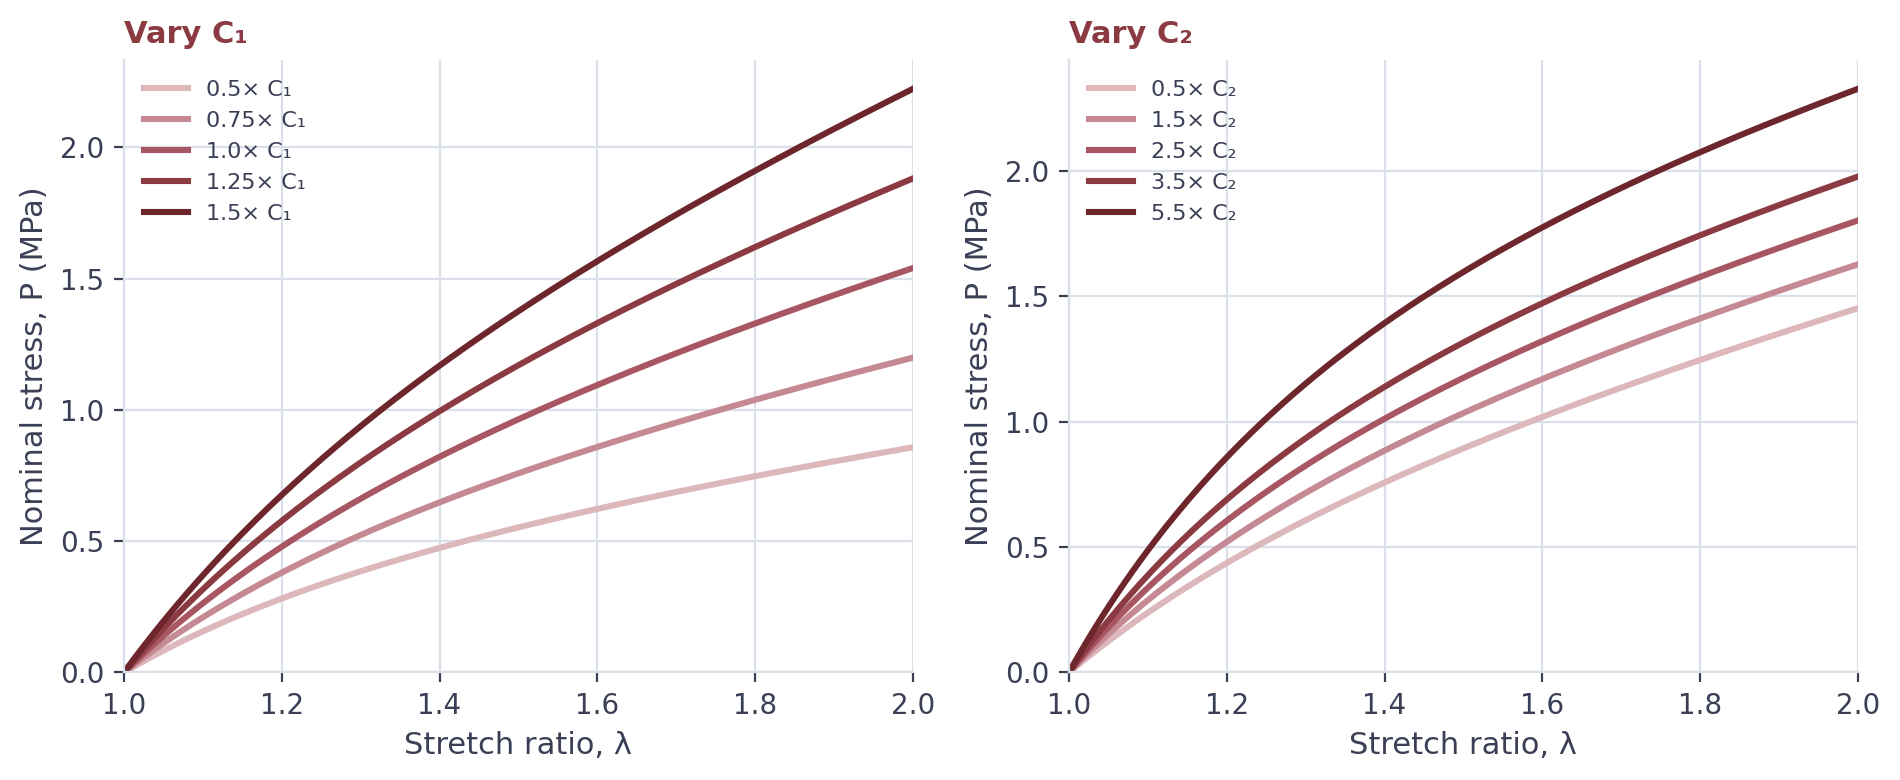

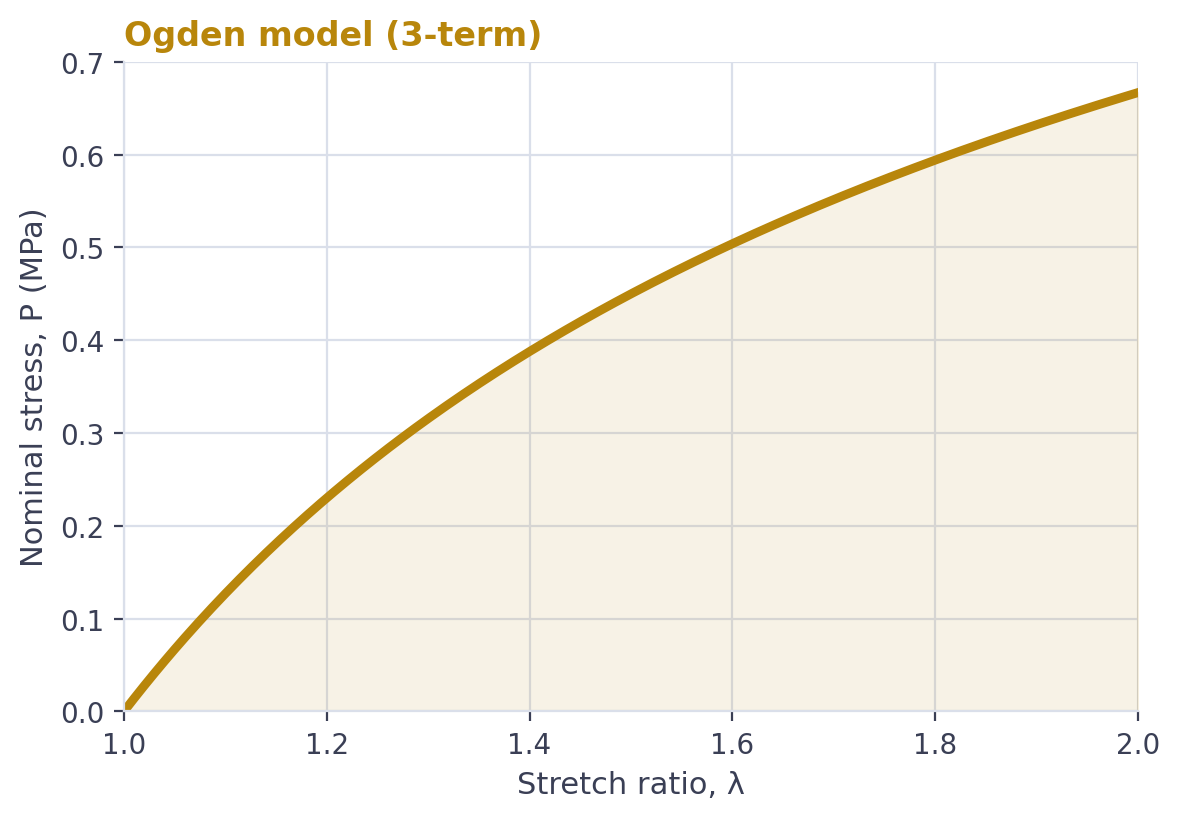

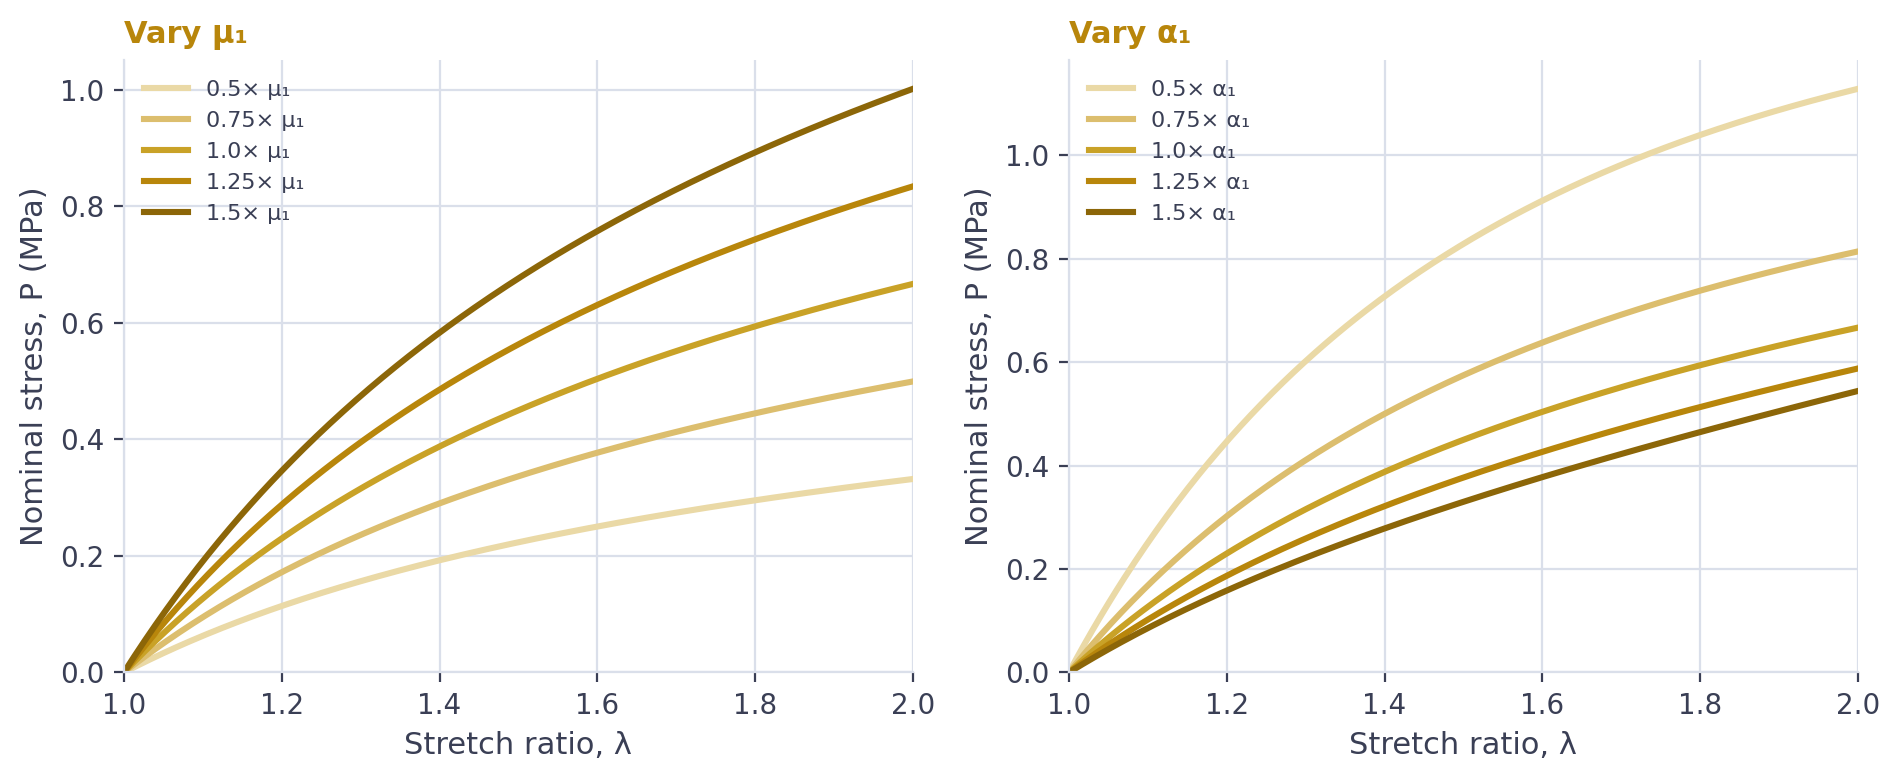

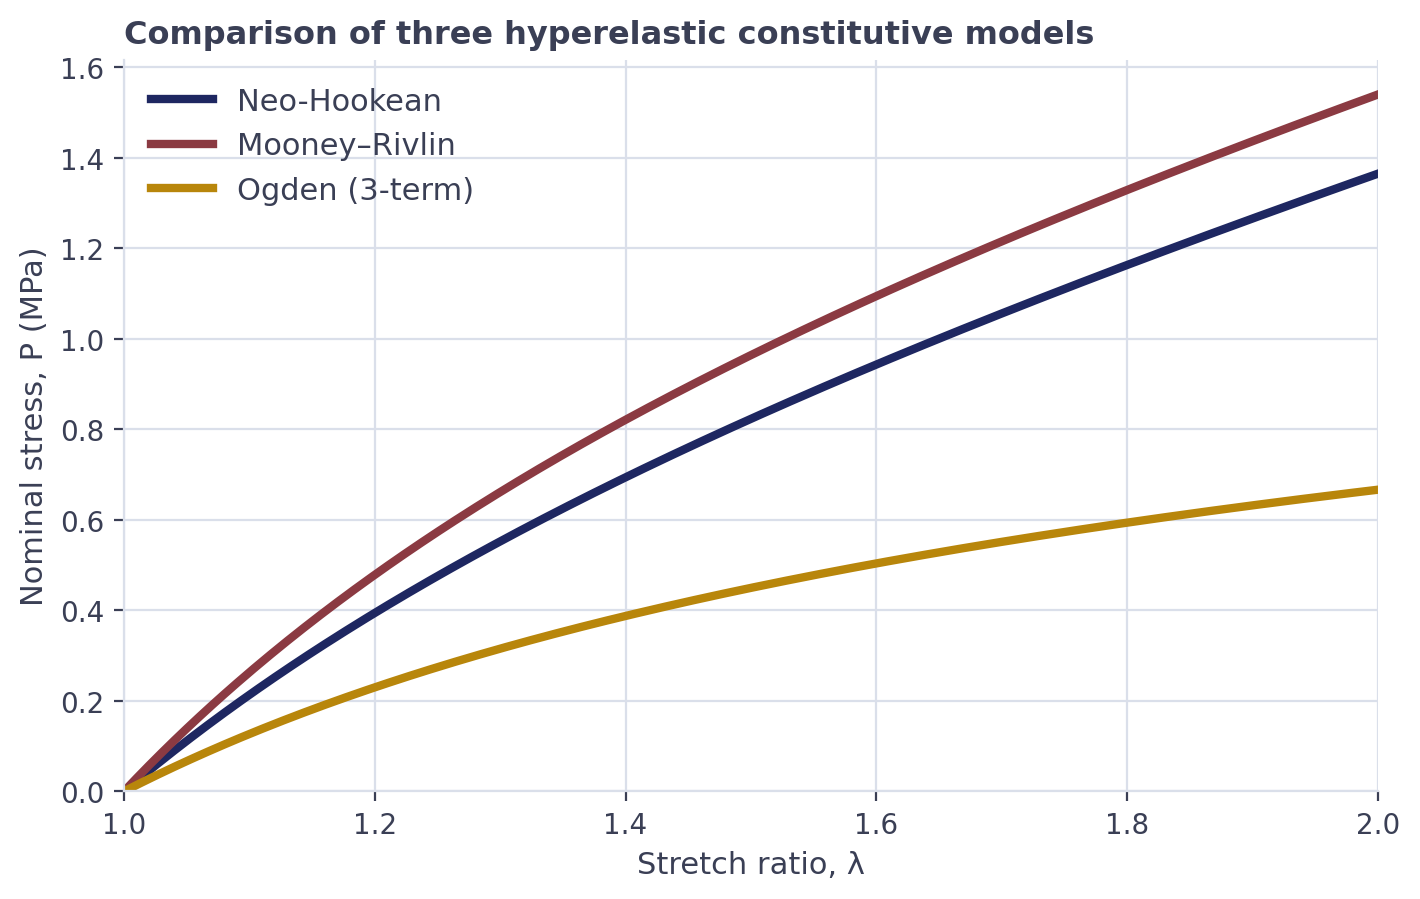

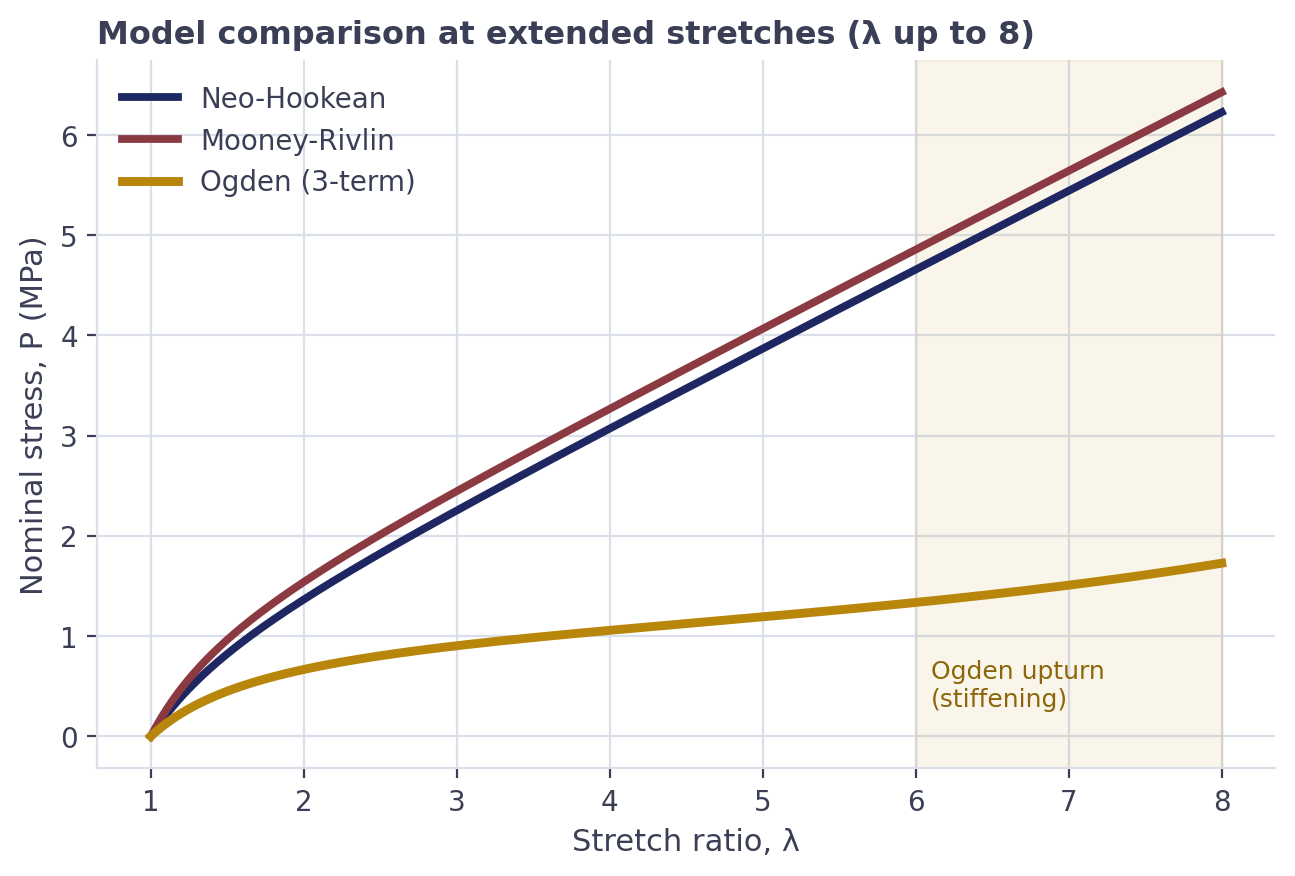

Initial Young's modulus check:
  Neo-Hookean : 2.340 MPa
  Mooney-Rivlin: 2.940 MPa
  Ogden        : 1.417 MPa
  Stress at lambda=2.0 -> NH=1.365 MPa, MR=1.540 MPa, Ogden=0.667 MPa


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ---------- palette (matches deck theme) ----------
NAVY   = "#1E2761"
MAROON = "#8B3A42"
GOLD   = "#B8860B"
GRID   = "#DADFEA"
TEXT   = "#3A3F55"

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "text.color": TEXT,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "svg.fonttype": "none",
})

lam = np.linspace(1.0, 2.0, 300)  # stretch 1.0 -> 2.0  (0% to 100% strain)

# ---------- model functions for uniaxial stress-stretch analysis ----------
def neo_hookean(lam, C1):
    return 2 * C1 * (lam - lam**-2)

def mooney_rivlin(lam, C1, C2):
    return 2 * C1 * (lam - lam**-2) + 2 * C2 * (1 - lam**-3)

# bit of oopsie
# def ogden(lam, mus, alphas):
#     sigma = np.zeros_like(lam)
#     for mu, a in zip(mus, alphas):
#         sigma += (2 * mu / a) * (lam**(a - 1) - lam**(-a/2 - 1))
#     return sigma

# # ---------- Corrected Ogden model function (Standard Form) ----------
# def ogden(lam, mus, alphas):
#     sigma = np.zeros_like(lam)
#     for mu, a in zip(mus, alphas):
#         sigma += mu * (lam**(a - 1) - lam**(-a/2 - 1))  # Removed 2*mu/a replaced with mu
#     return sigma

def ogden(lam, mus, alphas):
    sigma = np.zeros_like(lam, dtype=float)

    for mu, a in zip(mus, alphas):
        sigma += (2 * mu / a**2) * (
            lam**(a - 1) - lam**(-a/2 - 1)
        )

    return sigma

# ---------- base parameters (from the paper) ----------
C1_0 = 0.39                                    # MPa represents initial
C2_0 = 0.015                                   # MPa
C2_0 = 0.100                                   # MPa
# MU_0 = [0.62, 0.00118, 0.00981]                # MPa
AL_0 = [1.3, 5, -2]

def style_ax(ax, xlabel="Stretch ratio, λ", ylabel="Nominal stress, P (MPa)"):
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.set_xlim(1.0, 2.0)

# =====================================================================
# 1. Neo-Hookean main curve
# =====================================================================
fig, ax = plt.subplots(figsize=(6.0, 4.2), dpi=200)
sig = neo_hookean(lam, C1_0)
ax.plot(lam, sig, color=NAVY, lw=3.2)
ax.fill_between(lam, 0, sig, color=NAVY, alpha=0.08)
ax.set_ylim(0, None)
style_ax(ax)
ax.set_title(f"Neo-Hookean model   (C\u2081 = {C1_0} MPa)", fontsize=12, color=NAVY, weight="bold", loc="left")
plt.tight_layout()
plt.show()

# =====================================================================
# 2. Neo-Hookean sensitivity to C1
# =====================================================================
fig, ax = plt.subplots(figsize=(6.0, 4.2), dpi=200)
factors = [0.5, 0.75, 1.0, 1.25, 1.5]
navy_shades = ["#B9C0E0", "#8D98CC", "#5A69AC", "#2E3B85", "#1E2761"]
for f, c in zip(factors, navy_shades):
    ax.plot(lam, neo_hookean(lam, f * C1_0), color=c, lw=2.4, label=f"{f}\u00d7 C\u2081")
ax.set_ylim(0, None)
style_ax(ax)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Sensitivity to C\u2081 (0.5\u00d7 \u2013 1.5\u00d7)", fontsize=12, color=NAVY, weight="bold", loc="left")
plt.tight_layout()
plt.show()

# =====================================================================
# 3. Mooney-Rivlin main curve
# =====================================================================
fig, ax = plt.subplots(figsize=(6.0, 4.2), dpi=200)
sig = mooney_rivlin(lam, C1_0, C2_0)
ax.plot(lam, sig, color=MAROON, lw=3.2)
ax.fill_between(lam, 0, sig, color=MAROON, alpha=0.08)
ax.set_ylim(0, None)
style_ax(ax)
ax.set_title(f"Mooney\u2013Rivlin model   (C\u2081={C1_0}, C\u2082={C2_0} MPa)", fontsize=12, color=MAROON, weight="bold", loc="left")
plt.tight_layout()
plt.show()

# =====================================================================
# 4. Mooney-Rivlin sensitivity: C1 and C2 side-by-side
# =====================================================================
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.0), dpi=200)
maroon_shades = ["#DCB7BC", "#C48992", "#A85662", "#8B3A42", "#6E262D"]
c1_factors = [0.5, 0.75, 1.0, 1.25, 1.5]
for f, c in zip(c1_factors, maroon_shades):
    axs[0].plot(lam, mooney_rivlin(lam, f * C1_0, C2_0), color=c, lw=2.2, label=f"{f}\u00d7 C\u2081")
axs[0].set_ylim(0, None)
style_ax(axs[0])
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
axs[0].set_title("Vary C\u2081", fontsize=11, color=MAROON, weight="bold", loc="left")

c2_factors = [0.5, 1.5, 2.5, 3.5, 5.5]
for f, c in zip(c2_factors, maroon_shades):
    axs[1].plot(lam, mooney_rivlin(lam, C1_0, f * C2_0), color=c, lw=2.2, label=f"{f}\u00d7 C\u2082")
axs[1].set_ylim(0, None)
style_ax(axs[1])
axs[1].legend(frameon=False, fontsize=8, loc="upper left")
axs[1].set_title("Vary C\u2082", fontsize=11, color=MAROON, weight="bold", loc="left")
plt.tight_layout()
plt.show()

# =====================================================================
# 5. Ogden main curve
# =====================================================================
fig, ax = plt.subplots(figsize=(6.0, 4.2), dpi=200)
sig = ogden(lam, MU_0, AL_0)
ax.plot(lam, sig, color=GOLD, lw=3.2)
ax.fill_between(lam, 0, sig, color=GOLD, alpha=0.10)
ax.set_ylim(0, None)
style_ax(ax)
ax.set_title("Ogden model (3-term)", fontsize=12, color=GOLD, weight="bold", loc="left")
plt.tight_layout()
plt.show()

# =====================================================================
# 6. Ogden sensitivity: mu1 and alpha1 (dominant term) side-by-side
# =====================================================================
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.0), dpi=200)
gold_shades = ["#EAD9A6", "#DCBE6E", "#C9A227", "#B8860B", "#8C6608"]

mu1_factors = [0.5, 0.75, 1.0, 1.25, 1.5]
for f, c in zip(mu1_factors, gold_shades):
    mus = [f * MU_0[0], MU_0[1], MU_0[2]]
    axs[0].plot(lam, ogden(lam, mus, AL_0), color=c, lw=2.2, label=f"{f}\u00d7 \u03bc\u2081")
axs[0].set_ylim(0, None)
style_ax(axs[0])
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
axs[0].set_title("Vary \u03bc\u2081", fontsize=11, color=GOLD, weight="bold", loc="left")

a1_factors = [0.5, 0.75, 1.0, 1.25, 1.5]
for f, c in zip(a1_factors, gold_shades):
    als = [f * AL_0[0], AL_0[1], AL_0[2]]
    axs[1].plot(lam, ogden(lam, MU_0, als), color=c, lw=2.2, label=f"{f}\u00d7 \u03b1\u2081")
axs[1].set_ylim(0, None)
style_ax(axs[1])
axs[1].legend(frameon=False, fontsize=8, loc="upper left")
axs[1].set_title("Vary \u03b1\u2081", fontsize=11, color=GOLD, weight="bold", loc="left")
plt.tight_layout()
plt.show()

# =====================================================================
# 7. Comparison overlay: all three models
# =====================================================================
fig, ax = plt.subplots(figsize=(7.2, 4.6), dpi=200)
ax.plot(lam, neo_hookean(lam, C1_0), color=NAVY, lw=3.0, label="Neo-Hookean")
ax.plot(lam, mooney_rivlin(lam, C1_0, C2_0), color=MAROON, lw=3.0, label="Mooney\u2013Rivlin")
ax.plot(lam, ogden(lam, MU_0, AL_0), color=GOLD, lw=3.0, label="Ogden (3-term)")
ax.set_ylim(0, None)
style_ax(ax)
ax.legend(frameon=False, fontsize=11, loc="upper left")
ax.set_title(
    "Comparison of three hyperelastic constitutive models",
    fontsize=11.5, color=TEXT, weight="bold", loc="left"
)
plt.tight_layout()
plt.show()

# =====================================================================
# 8. Extended-range comparison (lambda up to 8): Ogden's late-stage
#    stiffening, invisible in the 0-100% strain window used above.
# =====================================================================
lam_ext = np.linspace(1.0, 8.0, 400)

fig, ax = plt.subplots(figsize=(7.6, 4.6), dpi=200)
ax.plot(lam_ext, neo_hookean(lam_ext, C1_0), color=NAVY, lw=2.8, label="Neo-Hookean")
ax.plot(lam_ext, mooney_rivlin(lam_ext, C1_0, C2_0), color=MAROON, lw=2.8, label="Mooney-Rivlin")
ax.plot(lam_ext, ogden(lam_ext, MU_0, AL_0), color=GOLD, lw=3.2, label="Ogden (3-term)")
ax.axvspan(6.0, 8.0, color=GOLD, alpha=0.08)
ax.text(6.1, 0.3, "Ogden upturn\n(stiffening)", fontsize=9, color="#8C6608")
ax.set_xlabel("Stretch ratio, \u03bb", fontsize=11)
ax.set_ylabel("Nominal stress, P (MPa)", fontsize=11)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=10, loc="upper left")
ax.set_title(
    "Model comparison at extended stretches (λ up to 8)",
    fontsize=11.5, color=TEXT, weight="bold", loc="left"
)
plt.show()

# ---------- print small-strain (initial) modulus check for the deck notes ----------
E0_nh = 6 * C1_0
E0_mr = 6 * (C1_0 + C2_0)
E0_og = 3 * sum(m / a for m, a in zip(MU_0, AL_0))
print("Initial Young's modulus check:")
print(f"  Neo-Hookean : {E0_nh:.3f} MPa")
print(f"  Mooney-Rivlin: {E0_mr:.3f} MPa")
print(f"  Ogden        : {E0_og:.3f} MPa")
print(f"  Stress at lambda=2.0 -> NH={neo_hookean(np.array([2.0]),C1_0)[0]:.3f} MPa, "
      f"MR={mooney_rivlin(np.array([2.0]),C1_0,C2_0)[0]:.3f} MPa, "
      f"Ogden={ogden(np.array([2.0]),MU_0,AL_0)[0]:.3f} MPa")

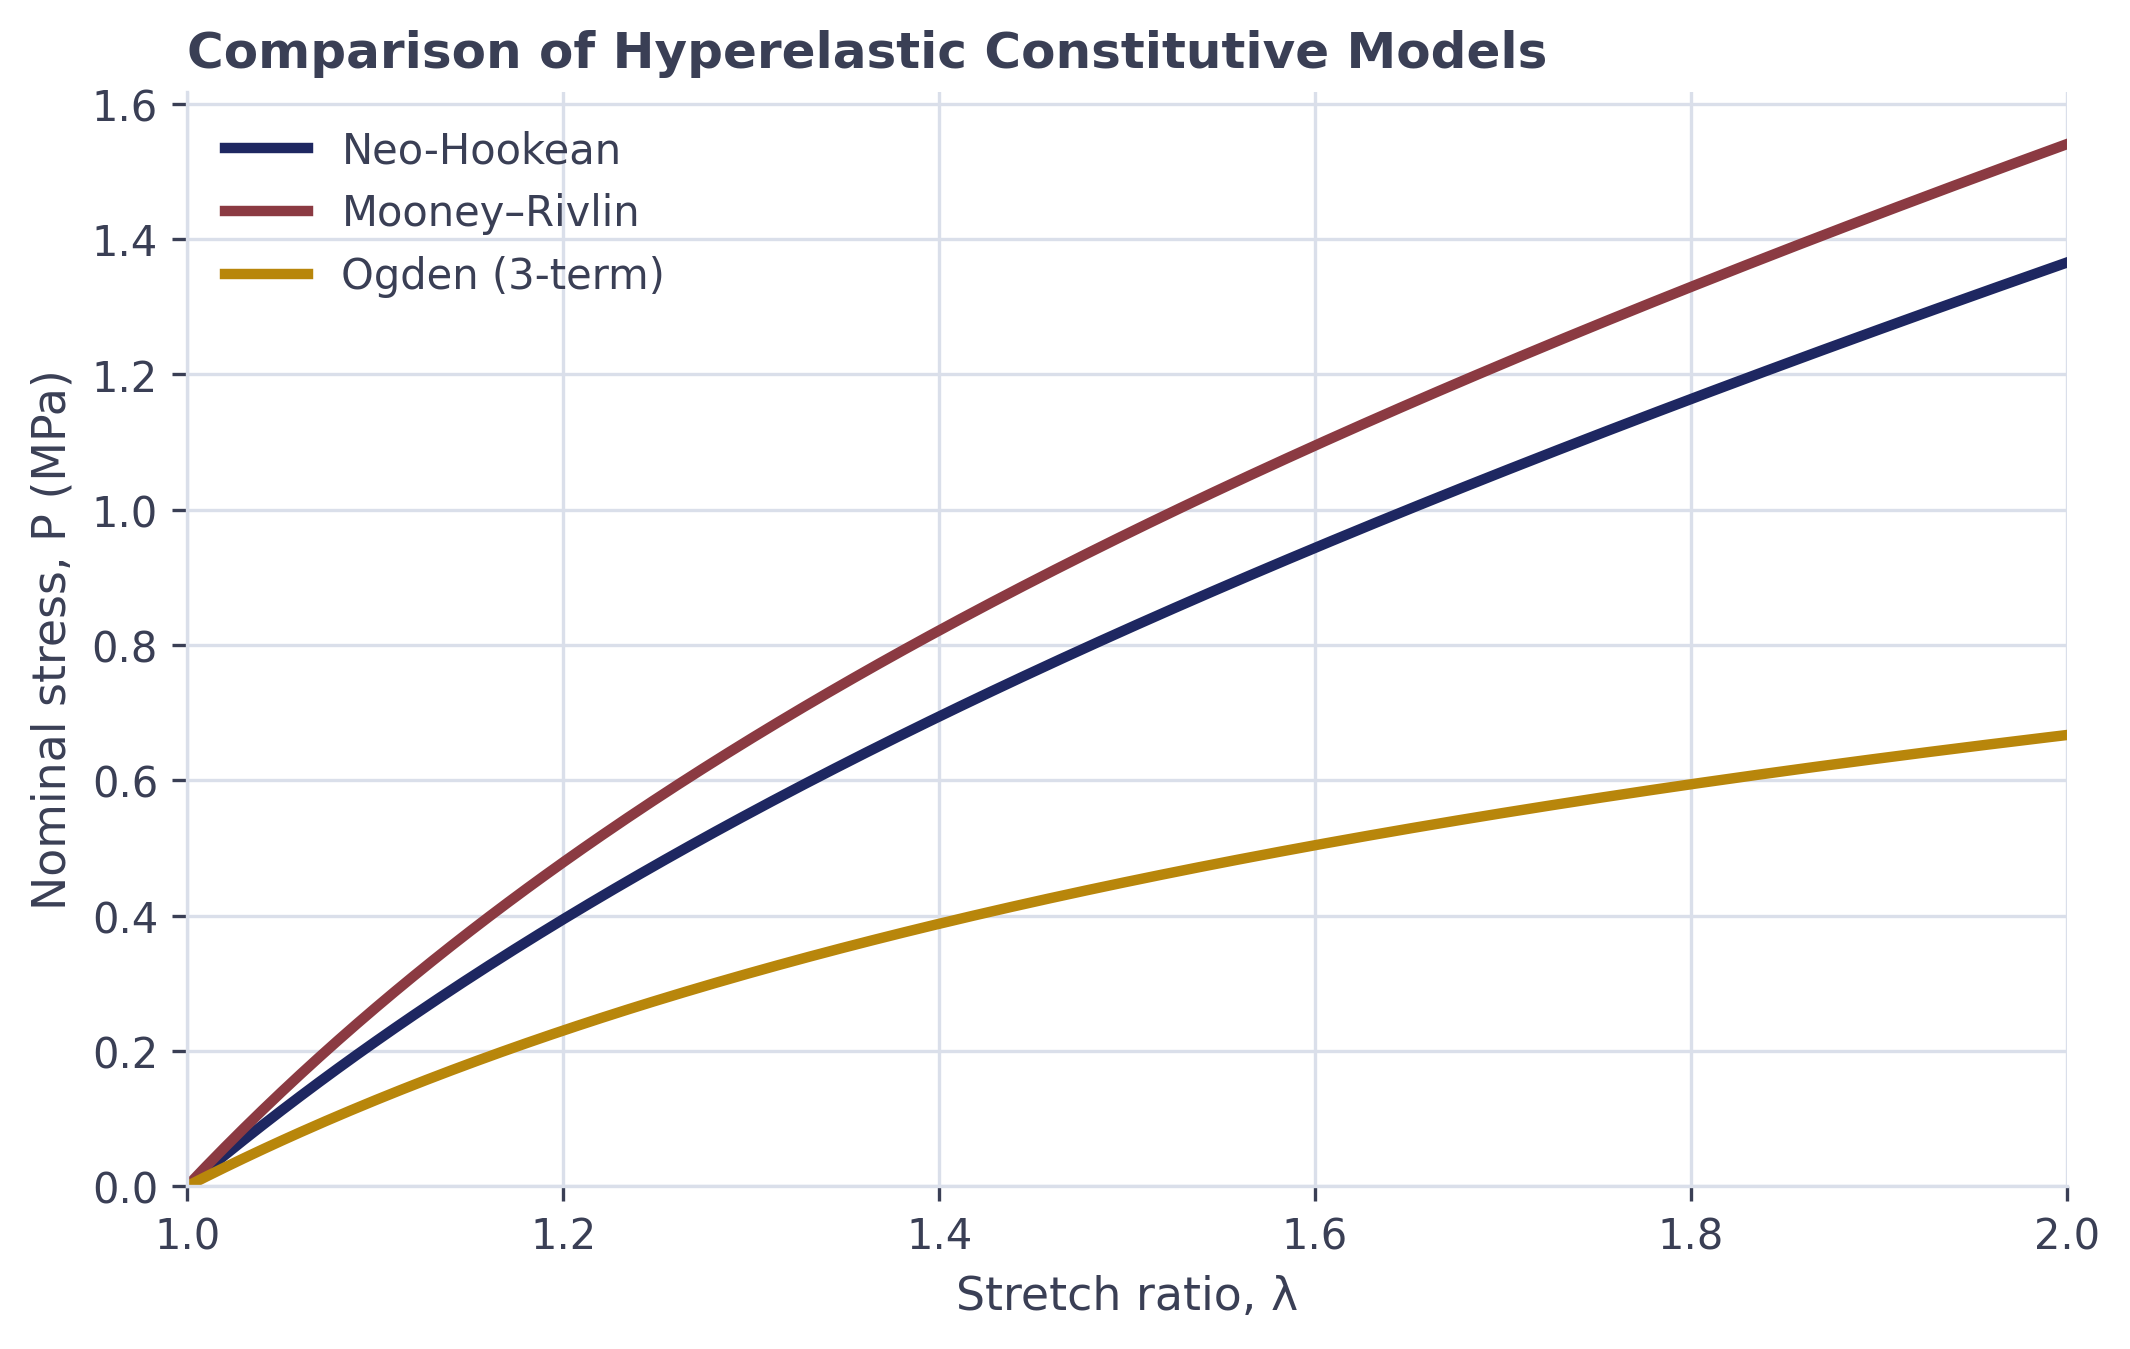

In [ ]:
# =====================================================================
# Figure 1. Comparison of hyperelastic constitutive models
# =====================================================================

fig, ax = plt.subplots(figsize=(7.2, 4.6), dpi=300)

# Calculate nominal stress using the existing model functions
stress_nh = neo_hookean(lam, C1_0)
stress_mr = mooney_rivlin(lam, C1_0, C2_0)
stress_ogden = ogden(lam, MU_0, AL_0)

# Plot all three constitutive responses
ax.plot(
    lam, stress_nh,
    color=NAVY, linewidth=2.5,
    label="Neo-Hookean"
)

ax.plot(
    lam, stress_mr,
    color=MAROON, linewidth=2.5,
    label="Mooney–Rivlin"
)

ax.plot(
    lam, stress_ogden,
    color=GOLD, linewidth=2.5,
    label="Ogden (3-term)"
)

# Labels and formatting
ax.set_xlabel("Stretch ratio, λ", fontsize=11)
ax.set_ylabel("Nominal stress, P (MPa)", fontsize=11)
ax.set_xlim(1.0, 2.0)
ax.set_ylim(bottom=0)

ax.set_title(
    "Comparison of Hyperelastic Constitutive Models",
    fontsize=12, weight="bold", loc="left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=10, loc="upper left")
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()

plt.show()